# What makes a team win La Liga?

**Data:** football-data.co.uk La Liga (`SP1`) match CSVs, 2015-16 to 2025-26 (11 seasons, 4,180 matches), in `data/raw/`.

**Method**
1. Turn every match into two team rows, then add them up into one row per team per season (220 team-seasons).
2. Rank each season by points and label each team **Champion** (1st), **Top 3** (2nd–3rd) or **Rest** (4th–20th).
3. Work out per-match averages for each metric (shots, shots on target, saves, …).
4. Standardise each metric **within its season** (z-scores), so a team is compared with the league it actually played in.
5. Compare the groups across all seasons. The metrics where champions stand out most, and most consistently, are the strongest signals.
6. Check this by correlating each metric with final points across **all** teams, because 11 champions is a small sample.

**How to read a z-score:** 0 = league average that season, +1 = one standard deviation above average, −1 = one below.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 2)

# Works whether the kernel starts in the project root or in notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"

GROUP_ORDER = ["Champion", "Top 3", "Rest"]
GROUP_COLORS = {"Champion": "#d4a017", "Top 3": "#4c72b0", "Rest": "#9a9a9a"}

## 2. Load matches

In [2]:
COLS = ["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "HTHG", "HTAG",
        "HS", "AS", "HST", "AST", "HF", "AF", "HC", "AC", "HY", "AY", "HR", "AR"]

frames = []
for f in sorted(DATA_DIR.glob("SP1_*.csv")):
    code = f.stem.split("_")[1]                       # e.g. "2324"
    frames.append(pd.read_csv(f, encoding="utf-8-sig", usecols=COLS).assign(Season=f"20{code[:2]}-{code[2:]}"))

matches = pd.concat(frames, ignore_index=True).dropna(subset=["FTHG", "FTAG"])
matches.shape

(4180, 20)

## 3. One row per team per match
Each match appears twice: once from the home team's side and once from the away team's side. For each row, "for" columns are that team's numbers and "against" columns are the opponent's.

In [3]:
def team_view(m, us, them, venue):
    """Match stats from one side's perspective. us/them are 'H' or 'A'."""
    return pd.DataFrame({
        "Season": m["Season"],
        "Team": m["HomeTeam"] if us == "H" else m["AwayTeam"],
        "Venue": venue,
        "GF": m[f"FT{us}G"], "GA": m[f"FT{them}G"],
        "Shots": m[f"{us}S"], "ShotsAg": m[f"{them}S"],
        "SoT": m[f"{us}ST"], "SoTAg": m[f"{them}ST"],
        "Corners": m[f"{us}C"], "CornersAg": m[f"{them}C"],
        "Fouls": m[f"{us}F"], "Yellows": m[f"{us}Y"], "Reds": m[f"{us}R"],
    })


team_matches = pd.concat([team_view(matches, "H", "A", "Home"),
                          team_view(matches, "A", "H", "Away")], ignore_index=True)
team_matches["Pts"] = np.select([team_matches.GF > team_matches.GA, team_matches.GF == team_matches.GA], [3, 1], 0)
team_matches.shape  # 2 rows per match

(8360, 15)

## 4. Season table, final position and group
Ties on points are broken by goal difference, then goals scored. (La Liga actually uses head-to-head first. The only tie at a group boundary is Atlético and Sevilla on 70 points in 2019-20, and Atlético finished 3rd either way.)

In [4]:
sum_cols = ["Pts", "GF", "GA", "Shots", "ShotsAg", "SoT", "SoTAg",
            "Corners", "CornersAg", "Fouls", "Yellows", "Reds"]
seasons = (team_matches.groupby(["Season", "Team"])[sum_cols].sum()
           .join(team_matches.groupby(["Season", "Team"]).size().rename("P"))
           .reset_index())
seasons["GD"] = seasons.GF - seasons.GA
seasons = seasons.sort_values(["Season", "Pts", "GD", "GF"], ascending=[True, False, False, False])
seasons["Pos"] = seasons.groupby("Season").cumcount() + 1
seasons["Group"] = np.select([seasons.Pos == 1, seasons.Pos <= 3], ["Champion", "Top 3"], "Rest")

# Sanity checks: 20 teams x 38 games per season
assert (seasons.groupby("Season").size() == 20).all() and (seasons.P == 38).all()
seasons.Group.value_counts()

Group
Rest        187
Top 3        22
Champion     11
Name: count, dtype: int64

In [5]:
# Champions and the rest of the top 3, per season
(seasons[seasons.Pos <= 3]
 .pivot(index="Season", columns="Pos", values="Team")
 .join(seasons[seasons.Pos == 1].set_index("Season")[["Pts"]].rename(columns={"Pts": "Champion pts"})))

,1,2,3,Champion pts
Season,,,,
2015-16,Barcelona,Real Madrid,Ath Madrid,91
2016-17,Real Madrid,Barcelona,Ath Madrid,93
2017-18,Barcelona,Ath Madrid,Real Madrid,93
2018-19,Barcelona,Ath Madrid,Real Madrid,87
2019-20,Real Madrid,Barcelona,Ath Madrid,87
2020-21,Ath Madrid,Real Madrid,Barcelona,86
2021-22,Real Madrid,Barcelona,Ath Madrid,86
2022-23,Barcelona,Real Madrid,Ath Madrid,88
2023-24,Real Madrid,Barcelona,Girona,95


## 5. Per-match metrics
Season totals divided by 38. "Shot share" is a team's shots as a % of all shots in its matches, which is a rough measure of how much it controls games.

There's no saves column in the data, so **saves** are estimated as *shots on target conceded − goals conceded*.

Metrics marked **uses goals** are partly calculated from goals, so they're closer to the outcome (and to points) than pure volume metrics.

In [6]:
per = lambda c: seasons[c] / seasons.P
saves = seasons.SoTAg - seasons.GA

metrics = pd.DataFrame({
    "Shots":            per("Shots"),
    "Shots on target":  per("SoT"),
    "Shot accuracy %":  seasons.SoT / seasons.Shots * 100,
    "Shot share %":     seasons.Shots / (seasons.Shots + seasons.ShotsAg) * 100,
    "SoT share %":      seasons.SoT / (seasons.SoT + seasons.SoTAg) * 100,
    "Goals per SoT":    seasons.GF / seasons.SoT,
    "Shots conceded":   per("ShotsAg"),
    "SoT conceded":     per("SoTAg"),
    "Saves":            saves / seasons.P,
    "Save %":           saves / seasons.SoTAg * 100,
    "Corners":          per("Corners"),
    "Corners conceded": per("CornersAg"),
    "Fouls":            per("Fouls"),
    "Yellow cards":     per("Yellows"),
    "Red cards":        per("Reds"),
})
METRICS = list(metrics.columns)
CATEGORY = {
    "Shots": "Attack", "Shots on target": "Attack", "Shot accuracy %": "Attack",
    "Shot share %": "Control", "SoT share %": "Control", "Corners": "Attack",
    "Goals per SoT": "Finishing (uses goals)", "Save %": "Goalkeeping (uses goals)",
    "Saves": "Goalkeeping (uses goals)", "Shots conceded": "Defence", "SoT conceded": "Defence",
    "Corners conceded": "Defence", "Fouls": "Discipline", "Yellow cards": "Discipline", "Red cards": "Discipline",
}

team_seasons = pd.concat([seasons[["Season", "Team", "Pos", "Group", "Pts"]], metrics], axis=1)

# Raw per-match averages by group (real units, before standardising)
team_seasons.groupby("Group")[METRICS].mean().T[GROUP_ORDER]

Group,Champion,Top 3,Rest
Shots,15.85,14.37,11.35
Shots on target,6.44,5.47,3.87
Shot accuracy %,40.78,37.96,34.10
Shot share %,61.66,57.22,48.40
SoT share %,66.02,60.87,47.47
Goals per SoT,0.36,0.36,0.30
Shots conceded,9.83,10.63,12.14
SoT conceded,3.30,3.46,4.29
Saves,2.50,2.53,2.90
Save %,75.64,73.19,67.63


## 6. Standardise within each season (z-scores)
Leagues change over time (e.g. shot volumes rise or fall). Standardising each metric within its own season means "how far above or below *that season's* league average was this team", so seasons can be pooled fairly.

In [7]:
z = team_seasons.copy()
z[METRICS] = team_seasons.groupby("Season")[METRICS].transform(lambda x: (x - x.mean()) / x.std())
z["Pts_z"] = team_seasons.groupby("Season").Pts.transform(lambda x: (x - x.mean()) / x.std())
z[["Season", "Team", "Group"] + METRICS[:5]].head()

,Season,Team,Group,Shots,Shots on target,Shot accuracy %,Shot share %,SoT share %
2,2015-16,Barcelona,Champion,1.87,2.41,2.49,2.06,2.14
13,2015-16,Real Madrid,Top 3,3.17,2.95,1.48,2.07,2.09
1,2015-16,Ath Madrid,Top 3,0.35,0.05,-0.42,1.10,1.52
19,2015-16,Villarreal,Rest,-1.34,-0.74,0.80,-1.12,0.02
0,2015-16,Ath Bilbao,Rest,0.03,-0.02,-0.02,0.80,0.55


## 7. Compare the groups across all seasons
- **Champion gap:** the champions' average z-score. Bigger in either direction means champions stand out more.
- **Gap vs top 3:** champion minus top 3. This shows what separates the winner from the other contenders, not just from everyone.
- **Consistency:** in how many of the 11 seasons the champion ranked in the league's top 3 on that metric (for metrics where lower is better, the bottom 3).

In [8]:
group_z = z.groupby("Group")[METRICS].mean().T[GROUP_ORDER]

league_rank = z.groupby("Season")[METRICS].rank(ascending=False)  # 1 = highest value that season
champ_rank = league_rank[z.Group == "Champion"]
direction = np.sign(group_z["Champion"])
consistency = pd.Series({
    m: (champ_rank[m] <= 3).mean() if direction[m] > 0 else (champ_rank[m] >= 18).mean()
    for m in METRICS
})

summary = pd.DataFrame({
    "Category": pd.Series(CATEGORY),
    "Champion gap (z)": group_z["Champion"],
    "Top 3 (z)": group_z["Top 3"],
    "Rest (z)": group_z["Rest"],
    "Gap vs top 3": group_z["Champion"] - group_z["Top 3"],
    "Champion in league top 3": consistency,
}).sort_values("Champion gap (z)", key=abs, ascending=False)

summary.style.format({c: "{:+.2f}" for c in ["Champion gap (z)", "Top 3 (z)", "Rest (z)", "Gap vs top 3"]}
                     | {"Champion in league top 3": "{:.0%}"}).background_gradient(
    subset=["Champion gap (z)", "Top 3 (z)", "Rest (z)"], cmap="RdBu_r", vmin=-2.5, vmax=2.5)

,Category,Champion gap (z),Top 3 (z),Rest (z),Gap vs top 3,Champion in league top 3
Shots on target,Attack,+2.38,+1.36,-0.30,+1.01,91%
SoT share %,Control,+2.10,+1.41,-0.29,+0.69,100%
Shots,Attack,+2.07,+1.28,-0.27,+0.79,100%
Shot share %,Control,+1.86,+1.15,-0.24,+0.71,82%
Shot accuracy %,Attack,+1.67,+0.91,-0.21,+0.76,64%
Fouls,Discipline,-1.51,-1.05,+0.21,-0.46,82%
Save %,Goalkeeping (uses goals),+1.40,+0.81,-0.18,+0.59,73%
Corners,Attack,+1.33,+1.02,-0.20,+0.31,55%
Yellow cards,Discipline,-1.27,-0.79,+0.17,-0.48,82%
SoT conceded,Defence,-1.26,-1.02,+0.19,-0.24,64%


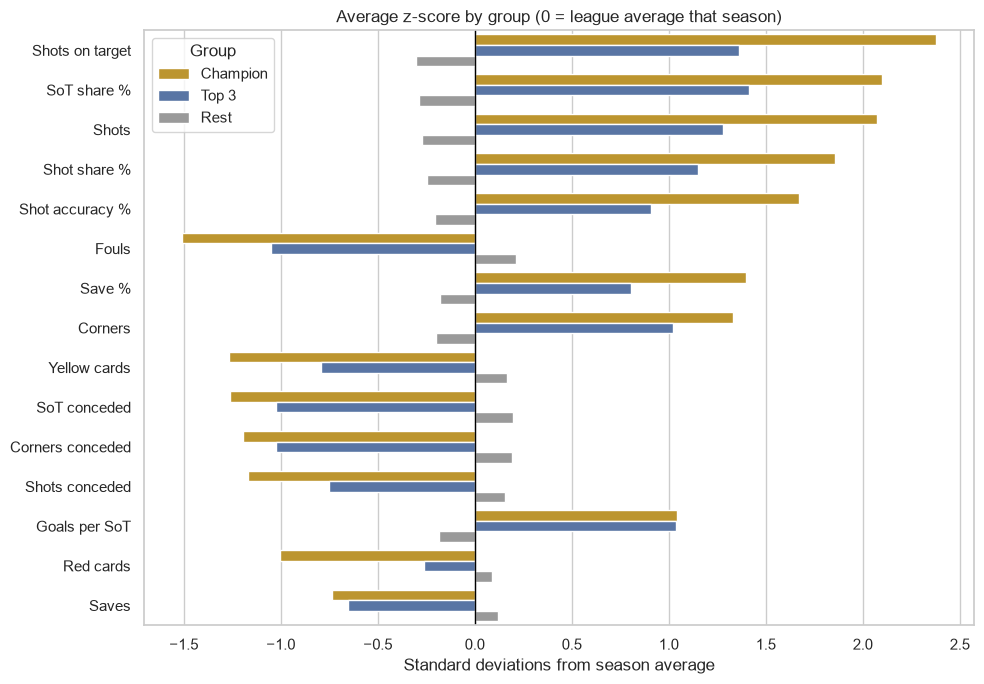

In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
order = summary.index
plot_df = group_z.loc[order].reset_index(names="Metric").melt(id_vars="Metric", var_name="Group", value_name="z")
sns.barplot(data=plot_df, y="Metric", x="z", hue="Group", hue_order=GROUP_ORDER,
            palette=GROUP_COLORS, ax=ax)
ax.axvline(0, color="black", lw=1)
ax.set_title("Average z-score by group (0 = league average that season)")
ax.set_xlabel("Standard deviations from season average")
ax.set_ylabel("")
plt.tight_layout()

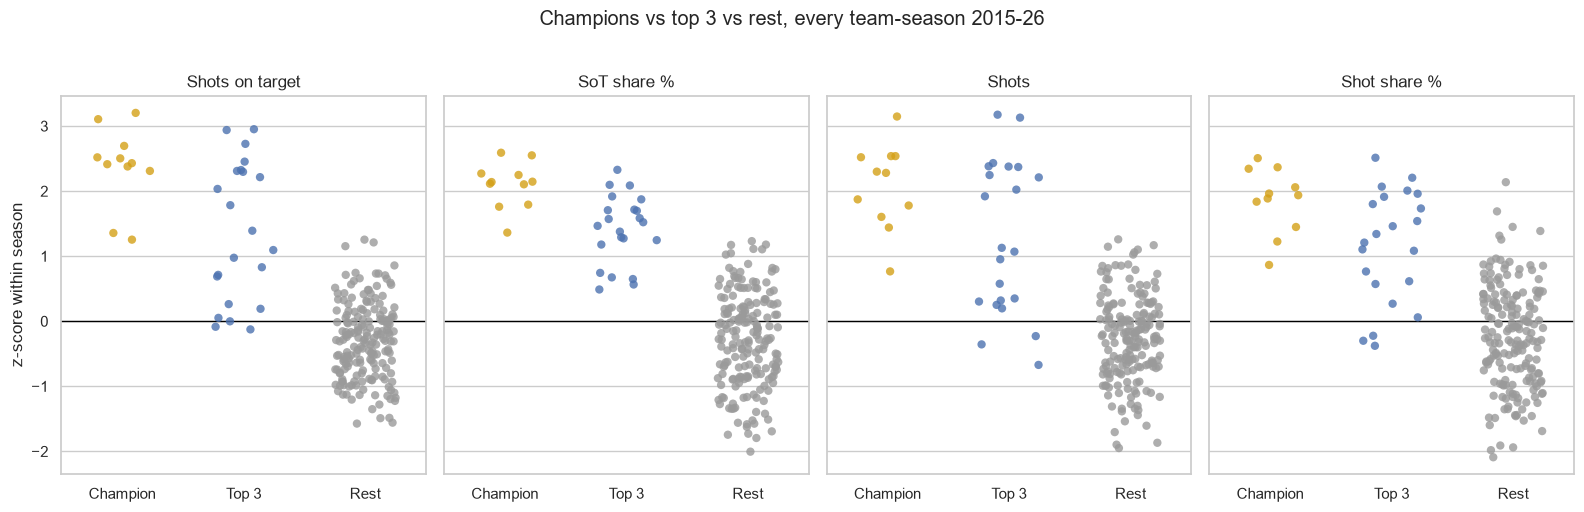

In [10]:
# Every team-season as a dot, for the four metrics where champions stand out most
top4 = summary.index[:4]
fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)
for ax, m in zip(axes, top4):
    sns.stripplot(data=z, x="Group", y=m, order=GROUP_ORDER, hue="Group",
                  palette=GROUP_COLORS, size=6, alpha=0.8, jitter=0.25, legend=False, ax=ax)
    ax.axhline(0, color="black", lw=1)
    ax.set_title(m)
    ax.set_xlabel("")
    ax.set_ylabel("z-score within season")
plt.suptitle("Champions vs top 3 vs rest, every team-season 2015-26", y=1.02)
plt.tight_layout()

## 8. Check across all 220 team-seasons
Eleven champions is a small sample. A metric that really matters should also track points for **every** team, not only the top. Here each metric's z-score is correlated with points (also standardised within season).

In [11]:
corr = z[METRICS].corrwith(z.Pts_z).rename("r with points")
check = summary[["Category", "Champion gap (z)"]].join(corr)
check["Agrees?"] = np.sign(check["Champion gap (z)"]) == np.sign(check["r with points"])
check.sort_values("r with points", key=abs, ascending=False)

,Category,Champion gap (z),r with points,Agrees?
SoT share %,Control,2.10,0.86,True
Shots on target,Attack,2.38,0.78,True
Shot share %,Control,1.86,0.69,True
SoT conceded,Defence,-1.26,-0.68,True
Shots,Attack,2.07,0.68,True
Goals per SoT,Finishing (uses goals),1.04,0.62,True
Shot accuracy %,Attack,1.67,0.61,True
Save %,Goalkeeping (uses goals),1.40,0.60,True
Corners,Attack,1.33,0.56,True
Shots conceded,Defence,-1.17,-0.53,True


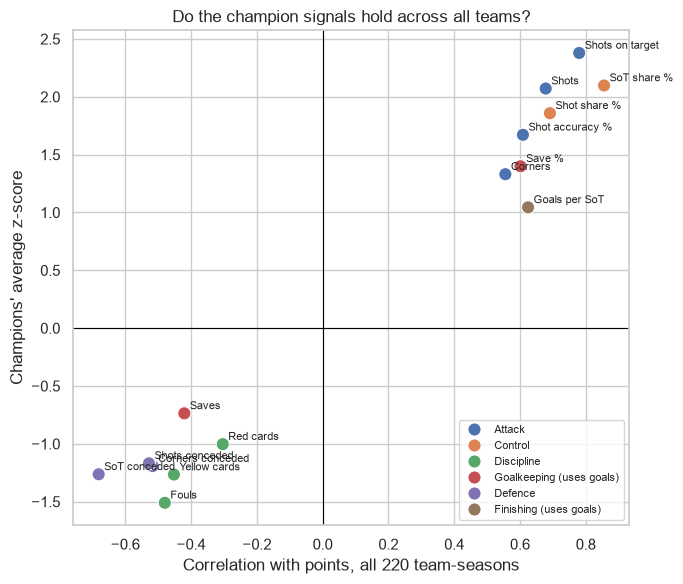

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=check, x="r with points", y="Champion gap (z)", hue="Category", s=90, ax=ax)
for m, row in check.iterrows():
    ax.annotate(m, (row["r with points"], row["Champion gap (z)"]), fontsize=8,
                xytext=(4, 3), textcoords="offset points")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Do the champion signals hold across all teams?")
ax.set_xlabel("Correlation with points, all 220 team-seasons")
ax.set_ylabel("Champions' average z-score")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()

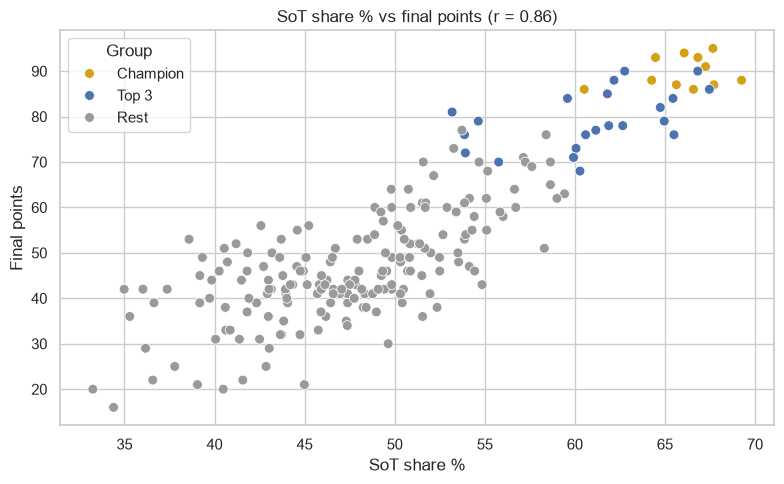

In [13]:
# The strongest single signal against points, coloured by group
best = check["r with points"].abs().idxmax()
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=team_seasons, x=best, y="Pts", hue="Group", hue_order=GROUP_ORDER,
                palette=GROUP_COLORS, s=50, ax=ax)
ax.set_title(f"{best} vs final points (r = {check.loc[best, 'r with points']:.2f})")
ax.set_ylabel("Final points")
plt.tight_layout()

## 9. Conclusion

**Takeaway: champions win the title by controlling matches and creating the most shots on target, not by finishing better.**

- **Shots on target is the biggest gap.** Champions averaged **6.4 shots on target per game, against 3.9 for the rest of the league**, about **+2.4 standard deviations** above their season's average. They ranked in the league's top 3 for it in 10 of 11 seasons.
- **Control matters most across all teams.** *SoT share*, a team's share of all shots on target in its matches, has the strongest link with points across all 220 team-seasons (**r ≈ 0.86**). Champions had about **66% of the shots on target in their games**, and the champion ranked top 3 for it in every season.
- **Finishing doesn't separate the winner from the other contenders.** Champions and the other top-3 teams convert the same share of shots on target (**0.36 goals per SoT**, z ≈ +1.0 for both). The difference between 1st and 2nd–3rd is how many chances they create, not how well they finish.
- **Defence and goalkeeping help, but less.** Champions face fewer shots and save a higher share (75.6% vs 67.6%). Their *number* of saves is lower, simply because they face fewer shots, which is a good example of why rates are more useful than counts.
- **Fewer fouls and cards.** Champions commit about 3 fewer fouls per game. This is probably a *result* of having the ball (you foul less when your opponent has it less), not a cause of winning.
- **The check agrees.** Every metric that marks out champions points the same way when correlated with points across the whole league, so these aren't quirks of 11 seasons.

**Caveats: this is correlation, not causation.**
- **Reverse causation:** good teams lead more often, and score lines change how both sides play. For example, a team that's losing chases the game and concedes more shots.
- **Hidden cause:** wages, transfer spending and squad quality probably drive both the stats and the points, and none of them are in this data. Only Barcelona, Real Madrid and Atlético won the title in these seasons, so "champion" is partly "rich club".
- **Small sample:** 11 champions from 3 clubs. The all-team correlations are the more reliable check.
- **Proxies:** saves are estimated (shots on target conceded − goals conceded). The data doesn't include possession or expected goals (xG).